## Hand Landmarks Model (Media Pipe)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from handspell.model_landmarks import create_landmarker, find_images, read_rgb, get_features, extract_features


In [3]:
landmarker = create_landmarker(min_hand_detection_confidence=0.1,
                               min_hand_presence_confidence=0.1)

MediaPipe model: ../models/hand_landmarker.task


I0000 00:00:1792500424.818202 6501166 init-domain.cc:134] Fiber init: default domain = pthread, concurrency = 8, prefix = pthread-default
INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792500424.830026 6501169 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792500424.838411 6501172 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [4]:
paths, labels = find_images()

In [5]:
paths

[PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__10.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__100.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1000.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1000_copy.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1001.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1001_copy.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1002_copy.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1003.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1003_copy.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004.jpg'),
 PosixPath('../data/dataset/D01_megadataset/A/A03_kaggle_asl__1004_copy.jpg'),
 PosixPath('../data

In [6]:
type(paths[0])

pathlib.PosixPath

In [7]:
labels

array([ 0,  0,  0, ..., 23, 23, 23], shape=(138199,))

In [8]:
rgb = read_rgb(paths[0])

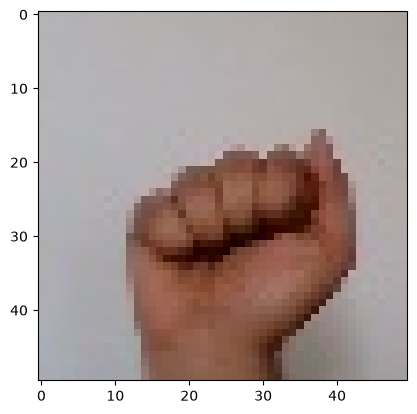

In [9]:
import matplotlib.pyplot as plt
plt.imshow(rgb)

In [10]:
type(landmarker)

mediapipe.tasks.python.vision.hand_landmarker.HandLandmarker

In [11]:
features, landmarks = get_features(rgb, landmarker)

W0000 00:00:1792500431.933900 6501174 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


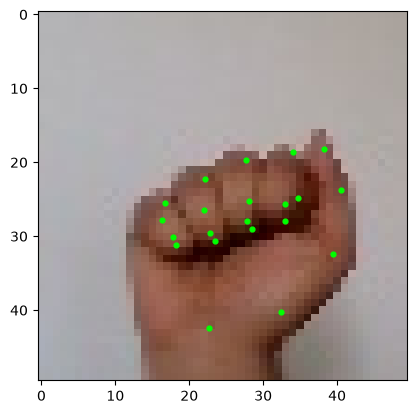

In [12]:
_, ax = plt.subplots(1,1)

ax.imshow(rgb)

if landmarks:
    height, width = rgb.shape[:2]
    ax.scatter(
        [point.x * width for point in landmarks],
        [point.y * height for point in landmarks],
        s=12,
        c="lime",
    )
    status = "detected"
else:
    status = "NO HAND"

In [13]:
features, failures = extract_features(paths)

W0000 00:00:1792500432.115215 6501250 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792500432.121412 6501250 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


MediaPipe model: ../models/hand_landmarker.task


  0%|          | 0/138199 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
features

array([[ 0.        ,  0.        ,  0.        , ..., -0.06812175,
        -0.65596855, -0.24931887],
       [ 0.        ,  0.        ,  0.        , ..., -0.04845177,
        -0.66427636, -0.2509724 ],
       [ 0.        ,  0.        ,  0.        , ..., -0.06770041,
        -0.6667545 , -0.24127516],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.05876412,
        -1.5596192 ,  0.34855425],
       [ 0.        ,  0.        ,  0.        , ..., -0.06551302,
        -1.5673888 ,  0.36658326],
       [ 0.        ,  0.        ,  0.        , ..., -0.08882862,
        -1.590285  ,  0.3357074 ]], shape=(1680, 63), dtype=float32)

In [ ]:
failures

[]

In [ ]:
# # STEP 1: Import the necessary modules.
# import mediapipe as mp
# from mediapipe.tasks import python
# from mediapipe.tasks.python import vision
# import cv2

# from handspell.model_landmarks import read_rgb


# # STEP 2: Create an HandLandmarker object.
# base_options = python.BaseOptions(model_asset_path='../models/hand_landmarker.task')
# options = vision.HandLandmarkerOptions(base_options=base_options,
#                                        num_hands=1)
# detector = vision.HandLandmarker.create_from_options(options)

# # STEP 3: Load the input image.
# image = mp.Image.create_from_file('../data/dataset/D02_original_aslmnist/A/B01_original_aslmnist__user_10__A0.jpg')

# # STEP 4: Detect hand landmarks from the input image.
# detection_result = detector.detect(image)

# # STEP 5: Process the classification result. In this case, visualize it.
# # annotated_image = draw_landmarks_on_image(image.numpy_view(), detection_result)
# # cv2_imshow(cv2.cvtColor(annotated_image, cv2.COLOR_RGB2BGR))

In [ ]:
# detection_result

In [ ]:
# #@markdown We implemented some functions to visualize the hand landmark detection results. <br/> Run the following cell to activate the functions.
# import mediapipe as mp
# import numpy as np


# mp_hands = mp.tasks.vision.HandLandmarksConnections
# mp_drawing = mp.tasks.vision.drawing_utils
# mp_drawing_styles = mp.tasks.vision.drawing_styles

# MARGIN = 10  # pixels
# FONT_SIZE = 1
# FONT_THICKNESS = 1
# HANDEDNESS_TEXT_COLOR = (88, 205, 54) # vibrant green

# def draw_landmarks_on_image(rgb_image, detection_result):
#   hand_landmarks_list = detection_result.hand_landmarks
#   handedness_list = detection_result.handedness
#   annotated_image = np.copy(rgb_image)

#   # Loop through the detected hands to visualize.
#   for idx in range(len(hand_landmarks_list)):
#     hand_landmarks = hand_landmarks_list[idx]
#     handedness = handedness_list[idx]

#     # Draw the hand landmarks.
#     mp_drawing.draw_landmarks(
#       annotated_image,
#       hand_landmarks,
#       mp_hands.HAND_CONNECTIONS,
#       mp_drawing_styles.get_default_hand_landmarks_style(),
#       mp_drawing_styles.get_default_hand_connections_style())

#     # Get the top left corner of the detected hand's bounding box.
#     height, width, _ = annotated_image.shape
#     x_coordinates = [landmark.x for landmark in hand_landmarks]
#     y_coordinates = [landmark.y for landmark in hand_landmarks]
#     text_x = int(min(x_coordinates) * width)
#     text_y = int(min(y_coordinates) * height) - MARGIN

#     # Draw handedness (left or right hand) on the image.
#     cv2.putText(annotated_image, f"{handedness[0].category_name}",
#                 (text_x, text_y), cv2.FONT_HERSHEY_DUPLEX,
#                 FONT_SIZE, HANDEDNESS_TEXT_COLOR, FONT_THICKNESS, cv2.LINE_AA)

#   return annotated_image